# C0 · ISBI 2015 · High · arm A: arm-level analysis only (§10)

Runs §10 of `C0_ISBI2015_High_A.ipynb` from the finished runs in `RUN_ROOT`, **without training and without a GPU**. Use it where
the arm A runs and the arm R runs of this tier sit together (locally: `weights/C0/ISBI2015_High`).

* Setup, run table and the frozen oval specification are copied verbatim from the training notebook; the protocol hash must be
  `093467c2293e4792` and the arm hash `47b9c6388cce8c42` (asserted).
* §10 is the training notebook's analysis code, unchanged except for one line in the run loader: the final checkpoint is verified
  against the SHA-256 in `DONE` when it is present, and may be missing (the analysis reads the saved test predictions only).
* Needed per arm A run: `DONE`, `predictions_test.csv.gz` (and `config.json`, `summary_final.csv`). Needed from arm R: the paired
  B0 runs `C0_ISBI2015_High_R_w1.00_s{1,2,3}` and, for the separability check, the `w0.50`, `w0.71`, `w1.41`, `w2.00` runs.
* Outputs go to `RUN_ROOT/arm_A_summary/`: `alpha_pooled.json`, `alpha_by_landmark.csv`, `accuracy_by_arm.csv`,
  `fail_by_ratio.csv`, `separability.csv`, `heatmap_shape.csv`, `arm_A_axis_observations.csv`, `arm_A_overview.png`.

In [1]:
import os
from pathlib import Path

DATASET = "ISBI 2015"
TIER = "High"
ARM = "A"

RUN_IDS = "all"         # "all" or a list of run_id strings from the run table (§1)
SMOKE_TEST = False      # True: synthetic data, tiny UNet, 4 epochs; checks the pipeline only, results meaningless

def _repo_root():
    """Walk up from the notebook folder to the repo root (the folder holding weights/ and data/)."""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "weights").is_dir() and (q / "data").is_dir():
            return q
    return None

_REPO = _repo_root()
# Inside the project's Docker image the repo is mounted at /tf; outside it, paths are found relative to the repo root.
DATA_ROOT = os.environ.get("ISBI_ROOT", "/tf/data/ISBI2015" if os.path.isdir("/tf/data/ISBI2015")
                           else str(_REPO / "data" / "ISBI2015") if _REPO else "data/ISBI2015")
RUN_ROOT = os.environ.get("C0_RUN_ROOT", "/tf/weights/C0/ISBI2015_High" if os.path.isdir("/tf/weights/C0/ISBI2015_High")
                          else str(_REPO / "weights" / "C0" / "ISBI2015_High") if _REPO else "weights/C0/ISBI2015_High")

SIGMA0_PX = 5.0         # σ₀ in canvas pixels (1.56 mm), confirmed by the arm R analysis of this tier
EPOCHS = 800
BATCH_SIZE = 4
NUM_WORKERS = 0         # no training in this notebook
GPU = None              # physical GPU index for this notebook (e.g. 0); None = all visible GPUs, training uses the first
PROGRESS_BAR = True     # one progress bar per run, advanced every epoch (loss, training-subset MRE, s/epoch, ETA)

In [2]:
import sys
if GPU is not None:
    # must happen before PyTorch initialises CUDA in this kernel
    if "torch" in sys.modules and sys.modules["torch"].cuda.is_initialized():
        raise RuntimeError("GPU can only be chosen before PyTorch starts: restart the kernel and run from the top.")
    os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU)
import json, math, re, time, hashlib, platform, subprocess, warnings, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

cv2.setNumThreads(0)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    # Fail fast if this PyTorch build has no kernels for the GPU (e.g. Blackwell sm_120 with a cu121/cu124 wheel)
    _maj, _min = torch.cuda.get_device_capability(0)
    _arch, _built = f"sm_{_maj}{_min}", torch.cuda.get_arch_list()
    if _arch not in _built:
        raise RuntimeError(f"{torch.cuda.get_device_name(0)} is {_arch}, but this PyTorch {torch.__version__} "
                           f"(CUDA {torch.version.cuda}) only has kernels for {_built}. For Blackwell (sm_120) install "
                           "PyTorch >= 2.7 built for CUDA >= 12.8, e.g. pip install --upgrade torch torchvision "
                           "--index-url https://download.pytorch.org/whl/cu128, then restart the kernel.")
    _ = (torch.ones(256, 256, device=DEVICE) @ torch.ones(256, 256, device=DEVICE)).sum().item()
if GPU is not None and DEVICE.type == "cuda":
    assert torch.cuda.device_count() == 1, f"expected only GPU {GPU} to be visible, got {torch.cuda.device_count()}"
if os.name == "nt" or SMOKE_TEST:
    NUM_WORKERS = 0          # notebook-defined Dataset classes cannot be pickled to spawned workers

LANDMARKS = ["sella", "nasion", "orbitale", "porion", "subspinale (A)", "supramentale (B)", "pogonion",
             "menton", "gnathion", "gonion", "lower incisal incision", "upper incisal incision", "upper lip",
             "lower lip", "subnasale", "soft-tissue pogonion", "posterior nasal spine", "anterior nasal spine",
             "articulare"]
K = len(LANDMARKS)

PROTOCOL = {
    # data
    "dataset": "ISBI 2015 cephalometric challenge (Wang et al., MedIA 2016)",
    "n_landmarks": K, "pixel_mm": 0.1,
    "split": {"train": [1, 150], "test1": [151, 300], "test2": [301, 400]},
    "ground_truth": "mean of senior and junior annotations",                         # PROVISIONAL
    "canvas_hw": [768, 640],
    "resize": "uniform scale s = min(768/H, 640/W); Gaussian pre-blur sigma 0.4/s; warpAffine bilinear, "
              "pixel-centre map x_c = s*(u+0.5)-0.5; zero pad right/bottom",
    "intensity": "[0,1] then per-sample z-score over the canvas",
    # network
    "tier": "High", "backbone": "UNet, base width 64, 4 levels, 3x3 conv + BN + ReLU, 2x2 transposed conv, "
                                "1x1 head, heatmaps at input resolution, no output activation",
    # target and loss
    "target": "unnormalised Gaussian exp(-0.5 d^T S^-1 d), peak 1, S in canvas px^2; the rotation part of the "
              "augmentation is applied to S (R S R^T), the scale part is not",
    "loss": "per-channel sum of squared error divided by that channel's analytic target mass 2*pi*sqrt(det S); "
            "landmarks outside the canvas after augmentation are excluded; mean over the remaining channels and batch",
    # optimisation
    "optimiser": {"name": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "warmup_epochs": 5,
                  "schedule": "cosine to 1e-6 per iteration"},                       # PROVISIONAL
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "drop_last": True,
    "amp": "bf16 autocast if supported, else fp16 with GradScaler",
    "augmentation": {"rot_deg": 10.0, "scale": [0.9, 1.1], "shift_frac": 0.05, "contrast": 0.2,
                     "brightness": 0.2, "gamma": [0.8, 1.25], "hflip": False},       # PROVISIONAL
    "seed_streams": "seed -> model init (torch); per-epoch order and per-sample augmentation from "
                    "numpy default_rng([seed, epoch, index]) so arms with equal seed see identical data",
    "checkpoint_used": "final epoch, no selection; fp16 snapshots at 50% and 75% for a post-hoc convergence report",
    "checkpoint_naming": "<stem>_<last 8 hex of the file's SHA-256>.pt (stem = final, snap_e50pct, snap_e75pct); "
                         "full SHA-256 in config.json; suffix re-verified on every load",
    "convergence_check": "MRE on 20 fixed training images (no augmentation) every 25 epochs; converged if the "
                         "mean of the last 4 checks is within 2% of the mean of the 4 before",
    # decoding and evaluation
    "decoders": ["argmax", "quadratic", "softargmax_local", "gaussfit"],
    "primary_decoder": "quadratic",                                                  # PROVISIONAL (fixed in WP0)
    "decoder_window_radius_px": 15,                                                  # PROVISIONAL, same in every arm
    "gross_failure_mm": 4.0, "sdr_mm": [2.0, 2.5, 3.0, 4.0],
    "error_frame": "original image, x right, y down, mm; angles from +x towards +y",
}

if SMOKE_TEST:
    RUN_ROOT = str(Path("c0_smoke_runs").resolve())
    DATA_ROOT = str(Path(RUN_ROOT) / "_synthetic_isbi")
    EPOCHS, SIGMA0_PX = 4, 1.5   # 4 so the 50% and 75% snapshots are distinct epochs
    PROTOCOL.update({"canvas_hw": [96, 80], "epochs": EPOCHS, "gross_failure_mm": 1e9,
                     "decoder_window_radius_px": 4, "smoke_test": True})
UNET_BASE = 8 if SMOKE_TEST else 64

PROTOCOL_HASH = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()[:16]
H_C, W_C = PROTOCOL["canvas_hw"]
MM = PROTOCOL["pixel_mm"]
R_WIN = PROTOCOL["decoder_window_radius_px"]
Path(RUN_ROOT).mkdir(parents=True, exist_ok=True)

def _git_commit():
    for d in ("/tf", "."):
        try:
            return subprocess.check_output(["git", "-C", d, "rev-parse", "HEAD"], stderr=subprocess.DEVNULL,
                                           text=True).strip()
        except Exception:
            pass
    return None

ENV_INFO = {
    "python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "gpu_arch": _arch if DEVICE.type == "cuda" else None,
    "torch_arch_list": torch.cuda.get_arch_list() if DEVICE.type == "cuda" else None,
    "opencv": cv2.__version__, "numpy": np.__version__, "git_commit": _git_commit(),
    "host": platform.node(), "cuda_visible_devices": os.environ.get("CUDA_VISIBLE_DEVICES"),
}
AMP_DTYPE = (torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else
             torch.float16 if DEVICE.type == "cuda" else None)
torch.backends.cudnn.benchmark = DEVICE.type == "cuda"
print("protocol", PROTOCOL_HASH, "| device", ENV_INFO["gpu"], "| amp", AMP_DTYPE, "| smoke", SMOKE_TEST)

protocol 093467c2293e4792 | device cpu | amp None | smoke False


In [3]:
RATIOS = {"1.50": 1.5, "2.00": 2.0, "3.00": 3.0, "4.00": 4.0}
ARM_LABEL = {"Apar": "A∥ (long axis along the baseline error axis)", "Aperp": "A⊥ (long axis across the baseline error axis)"}
PAIRED_SEEDS = [1, 2, 3]
B0_RUN = {s: f"C0_ISBI2015_{TIER}_R_w1.00_s{s}" for s in PAIRED_SEEDS}      # paired round baselines from arm R

def R_RUN(wlabel, seed):
    return f"C0_ISBI2015_{TIER}_R_w{wlabel}_s{seed}"

def _run_row(sub, rlabel, seed):
    r = RATIOS[rlabel]
    return {"run_id": f"C0_ISBI2015_{TIER}_{sub}_r{rlabel}_s{seed}", "dataset": DATASET, "tier": TIER, "arm": sub,
            "ratio_label": rlabel, "ratio": r, "width_mult": 1.0,
            "sigma_long_px": SIGMA0_PX * math.sqrt(r), "sigma_short_px": SIGMA0_PX / math.sqrt(r),
            "seed": seed, "paired_b0": B0_RUN[seed], "role": "oval"}

# Launch order = four waves of six (one run per notebook per wave). Wave 1 holds every seed-1 run at ratios 4 and 3, the ones most at
# risk of losing landmarks. A-par and A-perp alternate so that each GPU trains 6 + 6 runs and every ratio 3 times.
WAVES = [[("Apar", "4.00", 1), ("Aperp", "4.00", 1), ("Aperp", "3.00", 1), ("Apar", "3.00", 1), ("Apar", "2.00", 1), ("Aperp", "2.00", 1)],
         [("Aperp", "1.50", 1), ("Apar", "1.50", 1), ("Apar", "4.00", 2), ("Aperp", "4.00", 2), ("Aperp", "3.00", 2), ("Apar", "3.00", 2)],
         [("Apar", "2.00", 2), ("Aperp", "2.00", 2), ("Aperp", "1.50", 2), ("Apar", "1.50", 2), ("Apar", "4.00", 3), ("Aperp", "4.00", 3)],
         [("Aperp", "3.00", 3), ("Apar", "3.00", 3), ("Apar", "2.00", 3), ("Aperp", "2.00", 3), ("Aperp", "1.50", 3), ("Apar", "1.50", 3)]]
RUN_TABLE = pd.DataFrame([_run_row(*w) for wave in WAVES for w in wave])
RUN_TABLE.loc[RUN_TABLE.run_id == f"C0_ISBI2015_{TIER}_Apar_r4.00_s1", "role"] = "oval (first: ratio-4 pilot)"
assert len(RUN_TABLE) == 24 and RUN_TABLE.run_id.is_unique
assert all(sorted(g) == PAIRED_SEEDS for _, g in RUN_TABLE.groupby(["arm", "ratio_label"]).seed)
RUN_TABLE.to_csv(Path(RUN_ROOT) / "run_table_arm_A.csv", index=False)
RUN_TABLE[["run_id", "arm", "ratio", "sigma_long_px", "sigma_short_px", "seed", "paired_b0", "role"]]

,run_id,arm,ratio,sigma_long_px,sigma_short_px,seed,paired_b0,role
0,C0_ISBI2015_High_Apar_r4.00_s1,Apar,4.0,10.000000,2.500000,1,C0_ISBI2015_High_R_w1.00_s1,oval (first: ratio-4 pilot)
1,C0_ISBI2015_High_Aperp_r4.00_s1,Aperp,4.0,10.000000,2.500000,1,C0_ISBI2015_High_R_w1.00_s1,oval
2,C0_ISBI2015_High_Aperp_r3.00_s1,Aperp,3.0,8.660254,2.886751,1,C0_ISBI2015_High_R_w1.00_s1,oval
3,C0_ISBI2015_High_Apar_r3.00_s1,Apar,3.0,8.660254,2.886751,1,C0_ISBI2015_High_R_w1.00_s1,oval
4,C0_ISBI2015_High_Apar_r2.00_s1,Apar,2.0,7.071068,3.535534,1,C0_ISBI2015_High_R_w1.00_s1,oval
5,C0_ISBI2015_High_Aperp_r2.00_s1,Aperp,2.0,7.071068,3.535534,1,C0_ISBI2015_High_R_w1.00_s1,oval
6,C0_ISBI2015_High_Aperp_r1.50_s1,Aperp,1.5,6.123724,4.082483,1,C0_ISBI2015_High_R_w1.00_s1,oval
7,C0_ISBI2015_High_Apar_r1.50_s1,Apar,1.5,6.123724,4.082483,1,C0_ISBI2015_High_R_w1.00_s1,oval
8,C0_ISBI2015_High_Apar_r4.00_s2,Apar,4.0,10.000000,2.500000,2,C0_ISBI2015_High_R_w1.00_s2,oval
9,C0_ISBI2015_High_Aperp_r4.00_s2,Aperp,4.0,10.000000,2.500000,2,C0_ISBI2015_High_R_w1.00_s2,oval


In [4]:
# Baseline error axes of this tier, frozen by arm R: major-axis angle per landmark in degrees, image frame (from +x towards +y,
# y pointing down). Copied from baseline_axes_ISBI2015_High.csv; "image x-axis (placeholder)" landmarks have angle 0.
AXES_FILE = Path(RUN_ROOT) / "arm_R_summary" / f"baseline_axes_ISBI2015_{TIER}.csv"
AXES_SHA256 = "7812cffd969d1ed6615cc63dd51f8a502aca72f642465fe48e85b0fb65d528ad"
AXIS_ANGLE_DEG = [0.0, -64.3492519151323, -32.450246408066704, 0.0, 59.04461986173493, -68.3130789278577, -78.08116522672947, 4.955553673608648, -42.92964272845762, 57.32274065794502, 46.60746820049971, -19.937362645569262, 72.90743417879031, -46.89774995411713, -16.27417030363455, -69.28370111403308, 0.2459819927672129, 3.948085000516983, 81.5749105090758]
AXIS_DEFINED = [False, True, True, False, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]
AXIS_SD_RATIO = [1.1310871174587418, 2.127278209687187, 1.2215272431478617, 1.106737484470713, 2.0816934364046715, 2.8738584755050773, 3.6519151326899695, 2.615319415293904, 2.3644730208315208, 1.9000440869787485, 1.3278842474295809, 1.5827608479606594, 2.4712220634369046, 2.0690260044231668, 1.5992251921195226, 4.673753098120994, 1.523516492982358, 2.048649215367693, 1.7119227229997542]
assert len(AXIS_ANGLE_DEG) == len(AXIS_DEFINED) == len(AXIS_SD_RATIO) == K
if AXES_FILE.exists() and not SMOKE_TEST:
    _ax = pd.read_csv(AXES_FILE)
    assert np.allclose(_ax.angle_major_deg_used.values, AXIS_ANGLE_DEG, atol=1e-9) and \
        list(_ax.axis_defined.astype(bool)) == AXIS_DEFINED, f"{AXES_FILE} differs from the axes embedded here"
    _sha = hashlib.sha256(AXES_FILE.read_bytes()).hexdigest()
    print("baseline axes: embedded copy matches", AXES_FILE.name, "(file SHA-256", "matches)" if _sha == AXES_SHA256 else "differs, values equal)")
else:
    print("baseline axes: using the embedded copy (frozen file SHA-256 " + AXES_SHA256[:12] + "...)")

ARM_SPEC = {"arm": "A", "sub_arms": {"Apar": "long axis along the baseline error axis", "Aperp": "long axis at baseline axis + 90 deg"},
            "ratios": list(RATIOS.values()), "equal_area": "axes sigma0*sqrt(r) and sigma0/sqrt(r)", "sigma0_px": SIGMA0_PX,
            "axes_file": f"baseline_axes_ISBI2015_{TIER}.csv", "axes_sha256": AXES_SHA256, "axis_angle_deg": AXIS_ANGLE_DEG,
            "paired_b0": B0_RUN}
ARM_HASH = hashlib.sha256(json.dumps(ARM_SPEC, sort_keys=True).encode()).hexdigest()[:16]
print("arm hash", ARM_HASH)

baseline axes: embedded copy matches baseline_axes_ISBI2015_High.csv (file SHA-256 matches)
arm hash 47b9c6388cce8c42


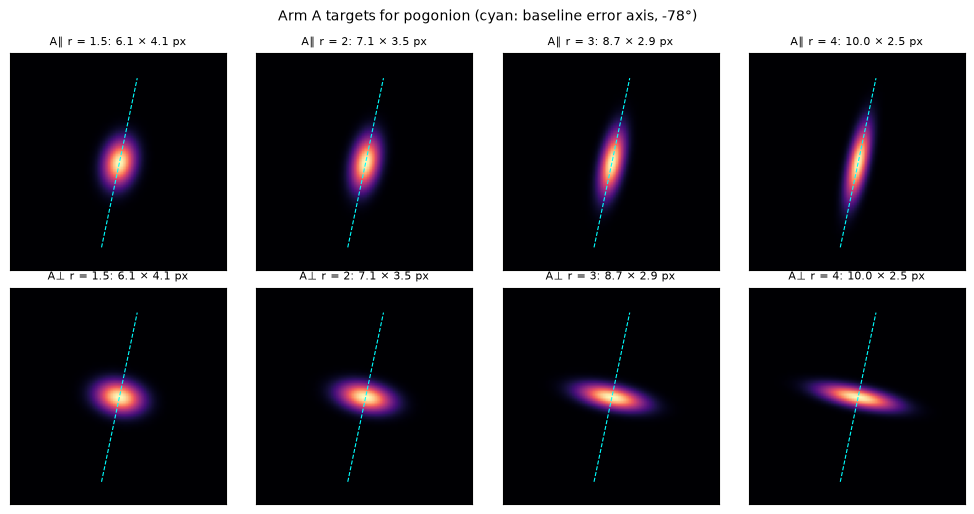

In [5]:
def arm_covariances(arm, width_mult, sigma0_px, k=K, ratio=1.0):
    """Per-landmark target covariance in the un-augmented canvas frame, px^2, shape (k, 2, 2).
    R: round, (w sigma0)^2 I.  Apar / Aperp: equal-area oval R(phi) diag(sigma0^2 r, sigma0^2 / r) R(phi)^T with phi = the
    landmark's baseline axis angle (Apar) or that angle + 90 degrees (Aperp); width_mult is not used (sigma_m = sigma0)."""
    if arm == "R":
        s = width_mult * sigma0_px
        return np.tile(np.eye(2) * s * s, (k, 1, 1))
    if arm in ("Apar", "Aperp"):
        phi = np.radians(np.asarray(AXIS_ANGLE_DEG[:k], float) + (0.0 if arm == "Apar" else 90.0))
        c, s = np.cos(phi), np.sin(phi)
        rot = np.stack([np.stack([c, -s], -1), np.stack([s, c], -1)], -2)          # (k, 2, 2), columns = long, short axis
        d = np.zeros((k, 2, 2)); d[:, 0, 0] = sigma0_px ** 2 * ratio; d[:, 1, 1] = sigma0_px ** 2 / ratio
        return rot @ d @ rot.transpose(0, 2, 1)
    raise NotImplementedError(f"arm {arm} is not defined in this notebook")

_YY = {}
def make_targets(pts, cov, H=None, W=None):
    """pts (B,K,2) canvas px [x,y]; cov (B,K,2,2). Returns (B,K,H,W) float32 Gaussians with peak 1."""
    H, W = H or H_C, W or W_C
    key = (H, W, str(pts.device))
    if key not in _YY:
        _YY[key] = (torch.arange(W, device=pts.device, dtype=torch.float32).view(1, 1, 1, W),
                    torch.arange(H, device=pts.device, dtype=torch.float32).view(1, 1, H, 1))
    xs, ys = _YY[key]
    inv = torch.linalg.inv(cov.float())
    dx = xs - pts[..., 0, None, None]
    dy = ys - pts[..., 1, None, None]
    q = inv[..., 0, 0, None, None] * dx * dx + 2 * inv[..., 0, 1, None, None] * dx * dy + inv[..., 1, 1, None, None] * dy * dy
    return torch.exp(-0.5 * q)

def in_canvas(pts, H=None, W=None):
    """(B,K) bool: landmark lies inside the canvas (after augmentation)."""
    H, W = H or H_C, W or W_C
    return (pts[..., 0] >= 0) & (pts[..., 0] <= W - 1) & (pts[..., 1] >= 0) & (pts[..., 1] <= H - 1)

def mass_normalised_mse(pred, target, cov, valid=None):
    """Per-channel SSE divided by the analytic target mass 2*pi*sqrt(det S), averaged over valid channels.
    The analytic mass does not shrink when a target is cut by the canvas border, and landmarks pushed off the
    canvas by augmentation (valid=False) are left out of that step's loss instead of dividing by a near-zero mass."""
    mass = 2 * math.pi * torch.sqrt(torch.linalg.det(cov.float()))
    se = ((pred.float() - target) ** 2).sum(dim=(2, 3))
    per = se / mass
    if valid is None:
        return per.mean()
    valid = valid.to(per.dtype)
    return (per * valid).sum() / valid.sum().clamp_min(1)

# checks: equal area (mass 2*pi*sigma0^2), long-axis direction and second moments of the rendered target, for every oval
p = torch.tensor([[[W_C / 2 + 0.3, H_C / 2 - 0.2]] * K], dtype=torch.float32)
_yy, _xx = np.mgrid[0:H_C, 0:W_C]
for sub in ("Apar", "Aperp"):
    for rl, r in RATIOS.items():
        cv = arm_covariances(sub, 1.0, SIGMA0_PX, ratio=r)
        assert np.allclose(np.sqrt(np.linalg.det(cv)), SIGMA0_PX ** 2), "oval area differs from the round baseline"
        ev, V = np.linalg.eigh(cv)
        ang = (np.degrees(np.arctan2(V[:, 1, 1], V[:, 0, 1])) + 90) % 180 - 90
        want = (np.asarray(AXIS_ANGLE_DEG) + (0 if sub == "Apar" else 90) + 90) % 180 - 90
        assert np.allclose(((ang - want) + 90) % 180 - 90, 0, atol=1e-6), "long axis is not at the intended angle"
        t = make_targets(p, torch.tensor(cv[None]))[0].numpy()
        for lm in (0, 6):                       # rendered second moments reproduce the covariance (sella, pogonion)
            w_ = t[lm] / t[lm].sum()
            mx, my = (w_ * _xx).sum(), (w_ * _yy).sum()
            emp = np.array([[(w_ * (_xx - mx) ** 2).sum(), (w_ * (_xx - mx) * (_yy - my)).sum()],
                            [(w_ * (_xx - mx) * (_yy - my)).sum(), (w_ * (_yy - my) ** 2).sum()]])
            assert np.allclose(emp, cv[lm], atol=0.05 * SIGMA0_PX ** 2 * r), (sub, rl, lm, emp, cv[lm])
            assert abs(t[lm].sum() / (2 * math.pi * SIGMA0_PX ** 2) - 1) < 0.02

LM_SHOW = 6                                    # pogonion: strongly anisotropic baseline errors
fig_t, axs = plt.subplots(2, 4, figsize=(10, 5.2))
p = torch.tensor([[[W_C / 2, H_C / 2]] * K], dtype=torch.float32)
half = min(int(4 * 2.0 * SIGMA0_PX) + 2, H_C // 2, W_C // 2)
for row, sub in enumerate(("Apar", "Aperp")):
    for ax, (rl, r) in zip(axs[row], RATIOS.items()):
        t = make_targets(p, torch.tensor(arm_covariances(sub, 1.0, SIGMA0_PX, ratio=r)[None]))[0, LM_SHOW].numpy()
        ax.imshow(t[H_C // 2 - half:H_C // 2 + half, W_C // 2 - half:W_C // 2 + half], cmap="magma", vmin=0, vmax=1)
        th = math.radians(AXIS_ANGLE_DEG[LM_SHOW])
        ax.plot([half - 0.8 * half * math.cos(th), half + 0.8 * half * math.cos(th)],
                [half - 0.8 * half * math.sin(th), half + 0.8 * half * math.sin(th)], color="cyan", lw=0.8, ls="--")
        ax.set_title(f"{'A∥' if sub == 'Apar' else 'A⊥'} r = {r:g}: {SIGMA0_PX * math.sqrt(r):.1f} × {SIGMA0_PX / math.sqrt(r):.1f} px",
                     fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
fig_t.suptitle(f"Arm A targets for {LANDMARKS[LM_SHOW]} (cyan: baseline error axis, {AXIS_ANGLE_DEG[LM_SHOW]:.0f}°)", fontsize=10)
fig_t.tight_layout()
fig_t.savefig(Path(RUN_ROOT) / "arm_A_targets.png", dpi=150)

In [6]:
import hashlib as _hl
def file_sha256(path, chunk=1 << 22):
    h = _hl.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()
CKPT_STATUS = {}
assert PROTOCOL_HASH == "093467c2293e4792", f"protocol hash {PROTOCOL_HASH} is not the one the runs used"
assert ARM_HASH == "47b9c6388cce8c42", f"arm hash {ARM_HASH} is not the one the runs used"
print("RUN_ROOT", RUN_ROOT)

RUN_ROOT C:\Users\nearl\Desktop\probable-umbrella\weights\C0\ISBI2015_High


## 10. Arm-level analysis (runs once all 24 oval runs and the three paired B0 runs are available)

Plan §5. Everything is a change relative to the paired round baseline B0 (arm R, `w1.00`, same seed), never an absolute direction.

* **Per run and landmark:** errors after the 4 mm gross-failure cut are projected onto the landmark's two baseline axes
  (u = baseline major axis, v = u + 90°). For A∥ the target's long axis is u, for A⊥ it is v. The spread is the SD along each axis;
  the sensitivity analysis uses 1.4826 × MAD.
* **Response:** Δ log SD along each target axis = log SD(oval run) − log SD(paired B0 run), same axis direction, same decoder.
* **Q1 (primary):** per landmark, OLS of Δ log SD on log(σ_d / σ₀) over its A∥ and A⊥ observations (two per run: long axis
  σ_d = σ₀√r, short axis σ_d = σ₀/√r), with an intercept. The slope is α_i. Pooled α = mean of α_i, one-sided t-test across
  landmarks; "transfer established" if the one-sided 95 % lower bound exceeds 0.1 (P0a).
* **P0b:** the same with A⊥ observations only, on landmarks with a defined axis and baseline SD ratio ≥ 1.3 (target and image disagree).
* **Usable cells** (same rule as arm R): an observation enters only if both the oval cell and its paired B0 cell have ≤ 5 % gross
  failures. Gross-failure rates per arm and ratio are reported separately (`fail_by_ratio.csv`), because an oval whose short axis is
  below the detectability floor is a result of its own.
* **Sensitivity:** all cells (no usable filter), MAD instead of SD, and the alternative decoders (`softargmax_local`, `gaussfit`, `argmax`).
* **Separability (ratios 2 and 4):** each oval axis's SD against the arm R run of the same width (1.41/0.71 and 2/0.5 × σ₀), same seed
  and axis direction. Needs those arm R runs in `RUN_ROOT`; skipped otherwise.
* **Heatmap shape:** the `gaussfit` decoder also fits the predicted heatmap's covariance; its long-axis angle is compared with the
  target's, which shows whether the network reproduces the oval at all.

The paired B0 runs come from arm R in the same `RUN_ROOT`. On a pod that only trained arm A, copy the three folders
`C0_ISBI2015_High_R_w1.00_s{1,2,3}` (and for separability the `w0.50`, `w0.71`, `w1.41`, `w2.00` runs) into `RUN_ROOT`, or run this
section locally where the arm R runs are.

In [7]:
def load_final_preds(rid, need_arm_hash):
    d = Path(RUN_ROOT) / rid
    if not (d / "DONE").exists():
        return None
    done = (d / "DONE").read_text().split()
    assert done[0] == PROTOCOL_HASH, f"{rid} ran under a different protocol"
    assert len(done) >= 3 and done[2].endswith(done[1][-11:-3]), f"{rid}: DONE marker is malformed"
    ck = d / done[1]
    if ck.exists():                     # analysis-only notebook: verify the checkpoint when it was copied, else rely on DONE
        assert file_sha256(ck) == done[2], f"{rid}: {ck.name} does not match the SHA-256 in DONE"
        CKPT_STATUS[rid] = "verified"
    else:
        CKPT_STATUS[rid] = "not present (DONE only)"
    if need_arm_hash:
        assert len(done) >= 4 and done[3] == ARM_HASH, f"{rid} was trained with a different oval specification (arm hash)"
    p = pd.read_csv(d / "predictions_test.csv.gz")
    return p[p.checkpoint == "final"]

A_PRED = {rid: load_final_preds(rid, True) for rid in RUN_TABLE.run_id}
B0_PRED = {s: load_final_preds(B0_RUN[s], False) for s in PAIRED_SEEDS}
R_PRED = {(wl, s): load_final_preds(R_RUN(wl, s), False) for wl in ("0.50", "0.71", "1.41", "2.00") for s in PAIRED_SEEDS}
n_done = sum(v is not None for v in A_PRED.values())
print("oval runs done:", n_done, "of", len(RUN_TABLE), "| paired B0 runs found:", sum(v is not None for v in B0_PRED.values()),
      "of 3 | arm R comparison runs found:", sum(v is not None for v in R_PRED.values()), "of 12")

oval runs done: 24 of 24 | paired B0 runs found: 3 of 3 | arm R comparison runs found: 12 of 12


In [8]:
AGG = Path(RUN_ROOT) / "arm_A_summary"
AGG.mkdir(exist_ok=True)
MAX_FAIL_CELL = 0.05      # a cell enters the alpha fit only if <= 5 % of its errors (and of its paired B0 cell's) exceed 4 mm
MIN_OBS = 8               # fewer usable axis observations than this -> no alpha_i for the landmark (max 48 per landmark)
P0B_MIN_SD_RATIO = 1.3    # plan P0b: landmarks where target and image disagree clearly
DECODERS = PROTOCOL["decoders"]
PD = PROTOCOL["primary_decoder"]
FAIL_MM = PROTOCOL["gross_failure_mm"]
_LOCK = AGG / ".analysis.lock"

def _acquire_lock(stale_s=3600):
    if _LOCK.exists() and time.time() - _LOCK.stat().st_mtime > stale_s:
        _LOCK.unlink(missing_ok=True)          # left behind by a crashed analysis
    try:
        os.close(os.open(_LOCK, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        return True
    except FileExistsError:
        print(f"another notebook is running the arm-level analysis now (or a stale lock is left at {_LOCK}); skipped here")
        return False

READY = n_done == len(RUN_TABLE) and all(v is not None for v in B0_PRED.values())
if not READY:
    print("arm-level analysis waits for:", [r for r, v in A_PRED.items() if v is None][:6],
          [B0_RUN[s] for s, v in B0_PRED.items() if v is None])
HAVE_LOCK = READY and _acquire_lock()

_th = np.radians(np.asarray(AXIS_ANGLE_DEG, float))
AX_U = np.stack([np.cos(_th), np.sin(_th)], 1)       # baseline major axis, image frame (x right, y down)
AX_V = np.stack([-np.sin(_th), np.cos(_th)], 1)      # u + 90 degrees

def _madsd_np(v):
    return 1.4826 * float(np.median(np.abs(v - np.median(v)))) if len(v) else np.nan

def axis_stats(pred):
    """Per decoder and landmark: failure rate, SD and MAD-SD along u and v after the gross-failure cut."""
    out = {}
    for (dec, lm), h in pred.groupby(["decoder", "landmark"]):
        keep = (h.r_mm <= FAIL_MM).values
        ex, ey = h.dx_mm.values[keep], h.dy_mm.values[keep]
        pu = ex * AX_U[lm - 1, 0] + ey * AX_U[lm - 1, 1]
        pv = ex * AX_V[lm - 1, 0] + ey * AX_V[lm - 1, 1]
        ok = keep.sum() >= 5
        out[(dec, lm)] = {"fail": float(1 - keep.mean()), "n_kept": int(keep.sum()),
                          "sd_u": float(np.std(pu, ddof=1)) if ok else np.nan, "sd_v": float(np.std(pv, ddof=1)) if ok else np.nan,
                          "mad_u": _madsd_np(pu) if ok else np.nan, "mad_v": _madsd_np(pv) if ok else np.nan}
    return out

def fit_alpha(obs, ycol):
    rows = []
    for lm in range(1, K + 1):
        g = obs[(obs.landmark == lm)]
        g = g[np.isfinite(g[ycol])]
        row = {"landmark": lm, "n_obs": len(g), "alpha": np.nan, "alpha_se": np.nan, "intercept": np.nan}
        if len(g) >= MIN_OBS and g.x.nunique() >= 3:
            (b1, b0), cv = np.polyfit(g.x, g[ycol], 1, cov=True)
            row.update({"alpha": b1, "alpha_se": math.sqrt(cv[0, 0]), "intercept": b0})
        rows.append(row)
    return pd.DataFrame(rows)

def pooled_alpha(a):
    a = np.asarray([v for v in a if np.isfinite(v)], float)
    n = len(a)
    if n < 3:
        return {"n_landmarks": n, "alpha": float(np.mean(a)) if n else None, "note": "fewer than 3 landmarks"}
    m, se = float(a.mean()), float(a.std(ddof=1) / math.sqrt(n))
    try:
        from scipy import stats as _st
        tq95, tq975 = _st.t.ppf(0.95, n - 1), _st.t.ppf(0.975, n - 1)
        p1 = float(_st.t.sf(m / se, n - 1)) if se > 0 else (0.0 if m > 0 else 1.0)
    except ImportError:                       # normal approximation if scipy is missing
        tq95, tq975 = 1.645, 1.96
        p1 = float(0.5 * math.erfc((m / se) / math.sqrt(2))) if se > 0 else (0.0 if m > 0 else 1.0)
    lo = m - tq95 * se
    verdict = ("transfer established (one-sided lower bound > 0.1)" if p1 < 0.05 and lo > 0.1 else
               "transfer detected but weak (alpha > 0, lower bound <= 0.1)" if p1 < 0.05 else
               "alpha < 0: sigma0 may be too narrow at many landmarks (plan: repeat aspect arms at 1.41 sigma0)"
               if m + tq975 * se < 0 else "no transfer detected")
    return {"n_landmarks": n, "alpha": round(m, 4), "se": round(se, 4), "t": round(m / se, 3) if se > 0 else None,
            "p_one_sided": round(p1, 5), "lower95_one_sided": round(lo, 4),
            "ci95": [round(m - tq975 * se, 4), round(m + tq975 * se, 4)], "verdict": verdict}

if HAVE_LOCK:
    try:
        B0S = {s: axis_stats(B0_PRED[s]) for s in PAIRED_SEEDS}
        rec = []
        for _, run in RUN_TABLE.iterrows():
            st = axis_stats(A_PRED[run.run_id])
            b0 = B0S[int(run.seed)]
            half = 0.5 * math.log(run.ratio)
            for (dec, lm), a in st.items():
                b = b0[(dec, lm)]
                major, minor = ("u", "v") if run.arm == "Apar" else ("v", "u")
                for axis, d, x in (("long", major, half), ("short", minor, -half)):
                    rec.append({"run_id": run.run_id, "arm": run.arm, "ratio": run.ratio, "seed": int(run.seed), "decoder": dec,
                                "landmark": lm, "axis": axis, "direction": d, "x": x,
                                "fail_oval": a["fail"], "fail_b0": b["fail"],
                                "sd_oval": a[f"sd_{d}"], "sd_b0": b[f"sd_{d}"],
                                "dlog_sd": math.log(a[f"sd_{d}"] / b[f"sd_{d}"]) if a[f"sd_{d}"] > 0 and b[f"sd_{d}"] > 0 else np.nan,
                                "dlog_mad": (math.log(a[f"mad_{d}"] / b[f"mad_{d}"])
                                             if a[f"mad_{d}"] > 0 and b[f"mad_{d}"] > 0 else np.nan)})
        OBS = pd.DataFrame(rec)
        OBS["usable"] = (OBS.fail_oval <= MAX_FAIL_CELL) & (OBS.fail_b0 <= MAX_FAIL_CELL) & OBS.dlog_sd.notna()
        OBS.to_csv(AGG / "arm_A_axis_observations.csv", index=False)

        P0B_LM = [lm for lm in range(1, K + 1) if AXIS_DEFINED[lm - 1] and AXIS_SD_RATIO[lm - 1] >= P0B_MIN_SD_RATIO]
        base = OBS[OBS.decoder == PD]
        variants = {
            "primary": (base[base.usable], "dlog_sd", None),
            "P0b_Aperp_disagreement": (base[base.usable & (base.arm == "Aperp")], "dlog_sd", P0B_LM),
            "Apar_only": (base[base.usable & (base.arm == "Apar")], "dlog_sd", None),
            "sens_all_cells": (base[base.dlog_sd.notna()], "dlog_sd", None),
            "sens_mad": (base[base.usable & base.dlog_mad.notna()], "dlog_mad", None),
        }
        for dec in DECODERS:
            if dec != PD:
                g = OBS[(OBS.decoder == dec)]
                variants[f"sens_decoder_{dec}"] = (g[g.usable], "dlog_sd", None)
        ALPHA = pd.DataFrame({"landmark": range(1, K + 1), "name": LANDMARKS, "axis_defined": AXIS_DEFINED,
                              "baseline_sd_ratio": AXIS_SD_RATIO, "in_P0b": [lm in P0B_LM for lm in range(1, K + 1)]})
        POOLED = {"protocol_hash": PROTOCOL_HASH, "arm_hash": ARM_HASH, "primary_decoder": PD, "max_fail_cell": MAX_FAIL_CELL,
                  "min_obs": MIN_OBS, "p0b_landmarks": [LANDMARKS[lm - 1] for lm in P0B_LM], "variants": {}}
        for name, (df, ycol, lms) in variants.items():
            fa = fit_alpha(df, ycol)
            if lms is not None:
                fa.loc[~fa.landmark.isin(lms), ["alpha", "alpha_se"]] = np.nan
            tag = "" if name == "primary" else "_" + name
            ALPHA[f"alpha{tag}"] = fa.alpha.values
            ALPHA[f"alpha_se{tag}"] = fa.alpha_se.values
            ALPHA[f"n_obs{tag}"] = fa.n_obs.values
            POOLED["variants"][name] = pooled_alpha(fa.alpha.values)
        ALPHA.to_csv(AGG / "alpha_by_landmark.csv", index=False)
        (AGG / "alpha_pooled.json").write_text(json.dumps(POOLED, indent=1))
        pa = POOLED["variants"]["primary"]
        print(f"P0a (primary): alpha = {pa.get('alpha')} over {pa['n_landmarks']} landmarks, one-sided p = {pa.get('p_one_sided')}, "
              f"lower 95 % bound = {pa.get('lower95_one_sided')} -> {pa.get('verdict')}")
        pb = POOLED["variants"]["P0b_Aperp_disagreement"]
        print(f"P0b (A-perp, SD ratio >= {P0B_MIN_SD_RATIO}): alpha = {pb.get('alpha')} over {pb['n_landmarks']} landmarks, "
              f"one-sided p = {pb.get('p_one_sided')} -> {pb.get('verdict')}")

        # accuracy and failures per arm and ratio (B0 = ratio 1)
        acc, fl = [], []
        for _, run in RUN_TABLE.iterrows():
            p = A_PRED[run.run_id]; p = p[p.decoder == PD]
            acc.append({"arm": run.arm, "ratio": run.ratio, "seed": int(run.seed), "mre_mm": p.r_mm.mean(),
                        **{f"sdr_{t:g}mm": (p.r_mm <= t).mean() for t in PROTOCOL["sdr_mm"]}, "fail_rate": (p.r_mm > FAIL_MM).mean()})
            fl += [{"arm": run.arm, "ratio": run.ratio, "seed": int(run.seed), "landmark": lm, "fail": (h.r_mm > FAIL_MM).mean()}
                   for lm, h in p.groupby("landmark")]
        for s in PAIRED_SEEDS:
            p = B0_PRED[s]; p = p[p.decoder == PD]
            acc.append({"arm": "B0", "ratio": 1.0, "seed": s, "mre_mm": p.r_mm.mean(),
                        **{f"sdr_{t:g}mm": (p.r_mm <= t).mean() for t in PROTOCOL["sdr_mm"]}, "fail_rate": (p.r_mm > FAIL_MM).mean()})
            fl += [{"arm": "B0", "ratio": 1.0, "seed": s, "landmark": lm, "fail": (h.r_mm > FAIL_MM).mean()}
                   for lm, h in p.groupby("landmark")]
        ACC = pd.DataFrame(acc)
        ACC_SUM = ACC.groupby(["arm", "ratio"]).mean(numeric_only=True).drop(columns="seed").reset_index()
        ACC_SUM.round(4).to_csv(AGG / "accuracy_by_arm.csv", index=False)
        FL = pd.DataFrame(fl)
        FAIL_TAB = FL.pivot_table(index="landmark", columns=["arm", "ratio"], values="fail", aggfunc="mean")
        FAIL_TAB.round(4).to_csv(AGG / "fail_by_ratio.csv")

        # does the predicted heatmap follow the target? (gaussfit covariance of the heatmap peak, canvas px)
        hm = []
        for _, run in RUN_TABLE.iterrows():
            p = A_PRED[run.run_id]; p = p[(p.decoder == "gaussfit") & p.fit_sxx.notna()]
            if not len(p):
                continue
            sxx, sxy, syy = p.fit_sxx.values, p.fit_sxy.values, p.fit_syy.values
            ang = 0.5 * np.degrees(np.arctan2(2 * sxy, sxx - syy))
            tr, det = sxx + syy, sxx * syy - sxy ** 2
            l1, l2 = tr / 2 + np.sqrt(np.maximum(tr ** 2 / 4 - det, 0)), tr / 2 - np.sqrt(np.maximum(tr ** 2 / 4 - det, 0))
            tgt = np.asarray(AXIS_ANGLE_DEG)[p.landmark.values - 1] + (0 if run.arm == "Apar" else 90)
            dang = (ang - tgt + 90) % 180 - 90
            hm.append({"arm": run.arm, "ratio": run.ratio, "seed": int(run.seed),
                       "heatmap_axis_error_deg_median": float(np.median(np.abs(dang))),
                       "heatmap_sd_ratio_median": float(np.median(np.sqrt(np.maximum(l1, 1e-12) / np.maximum(l2, 1e-12))))})
        HM = pd.DataFrame(hm)
        if len(HM):
            HM.groupby(["arm", "ratio"]).median(numeric_only=True).drop(columns="seed").round(3).to_csv(AGG / "heatmap_shape.csv")

        # separability: each oval axis against the arm R run of the same width (ratios 2 and 4)
        SEP = None
        WMAP = {2.0: ("1.41", "0.71"), 4.0: ("2.00", "0.50")}
        if all(R_PRED[(wl, s)] is not None for pair in WMAP.values() for wl in pair for s in PAIRED_SEEDS):
            RS = {k: axis_stats(v) for k, v in R_PRED.items()}
            sep = []
            for _, run in RUN_TABLE[RUN_TABLE.ratio.isin(list(WMAP))].iterrows():
                st = axis_stats(A_PRED[run.run_id])
                w_long, w_short = WMAP[run.ratio]
                major, minor = ("u", "v") if run.arm == "Apar" else ("v", "u")
                for lm in range(1, K + 1):
                    a = st[(PD, lm)]
                    for axis, d, wl in (("long", major, w_long), ("short", minor, w_short)):
                        r_ = RS[(wl, int(run.seed))][(PD, lm)]
                        ok = a["fail"] <= MAX_FAIL_CELL and r_["fail"] <= MAX_FAIL_CELL and a[f"sd_{d}"] > 0 and r_[f"sd_{d}"] > 0
                        sep.append({"arm": run.arm, "ratio": run.ratio, "seed": int(run.seed), "landmark": lm, "axis": axis,
                                    "round_width": wl, "dlog_sd_vs_round": math.log(a[f"sd_{d}"] / r_[f"sd_{d}"]) if ok else np.nan})
            SEP = pd.DataFrame(sep)
            SEP_SUM = (SEP.dropna().groupby(["ratio", "axis", "round_width", "landmark"]).dlog_sd_vs_round.mean()
                       .groupby(level=[0, 1, 2]).agg(["median", "count"]).rename(columns={"count": "n_landmarks"}))
            SEP_SUM.round(4).to_csv(AGG / "separability.csv")
            print("separability (median over landmarks of log SD_oval_axis - log SD_round_same_width; 0 = axis behaves like its own width):")
            display(SEP_SUM.round(3))
        else:
            print("separability skipped: arm R runs at 0.5, 0.71, 1.41 and 2 x sigma0 not all found in RUN_ROOT")
        display(ACC_SUM.round(3))
        display(ALPHA[["name", "in_P0b", "alpha", "alpha_se", "n_obs", "alpha_P0b_Aperp_disagreement", "alpha_sens_mad"]].round(3))
    except BaseException:
        _LOCK.unlink(missing_ok=True)
        HAVE_LOCK = False
        raise

P0a (primary): alpha = 0.0642 over 15 landmarks, one-sided p = 0.0, lower 95 % bound = 0.0484 -> transfer detected but weak (alpha > 0, lower bound <= 0.1)
P0b (A-perp, SD ratio >= 1.3): alpha = 0.1091 over 13 landmarks, one-sided p = 8e-05 -> transfer detected but weak (alpha > 0, lower bound <= 0.1)
separability (median over landmarks of log SD_oval_axis - log SD_round_same_width; 0 = axis behaves like its own width):


median  n_landmarks
ratio axis  round_width                     
2.0   long  1.41         -0.017           15
      short 0.71         -0.020           15
4.0   long  2.00          0.029           15
      short 0.50          0.003           11

,arm,ratio,mre_mm,sdr_2mm,sdr_2.5mm,sdr_3mm,sdr_4mm,fail_rate
0,Apar,1.5,1.369,0.819,0.881,0.923,0.965,0.035
1,Apar,2.0,1.307,0.818,0.881,0.922,0.967,0.033
2,Apar,3.0,1.310,0.823,0.883,0.922,0.967,0.033
3,Apar,4.0,1.299,0.813,0.878,0.917,0.964,0.036
4,Aperp,1.5,1.462,0.814,0.878,0.923,0.965,0.035
5,Aperp,2.0,1.629,0.813,0.876,0.920,0.964,0.036
6,Aperp,3.0,1.515,0.806,0.871,0.915,0.962,0.038
7,Aperp,4.0,1.678,0.805,0.868,0.913,0.961,0.039
8,B0,1.0,1.420,0.816,0.880,0.922,0.965,0.035


,name,in_P0b,alpha,alpha_se,n_obs,alpha_P0b_Aperp_disagreement,alpha_sens_mad
0,sella,False,0.087,0.026,48,NaN,0.080
1,nasion,True,0.006,0.033,48,0.102,0.050
2,orbitale,False,0.031,0.013,48,NaN,0.028
3,porion,False,NaN,NaN,0,NaN,NaN
4,subspinale (A),True,0.081,0.015,48,0.122,0.109
5,supramentale (B),True,NaN,NaN,0,NaN,NaN
6,pogonion,True,0.100,0.027,48,0.187,0.077
7,menton,True,0.013,0.022,48,0.008,0.078
8,gnathion,True,0.090,0.030,48,0.219,0.137
9,gonion,True,NaN,NaN,0,NaN,NaN


### Figure: transfer curve, α per landmark, gross failures by ratio

<cell 9>:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


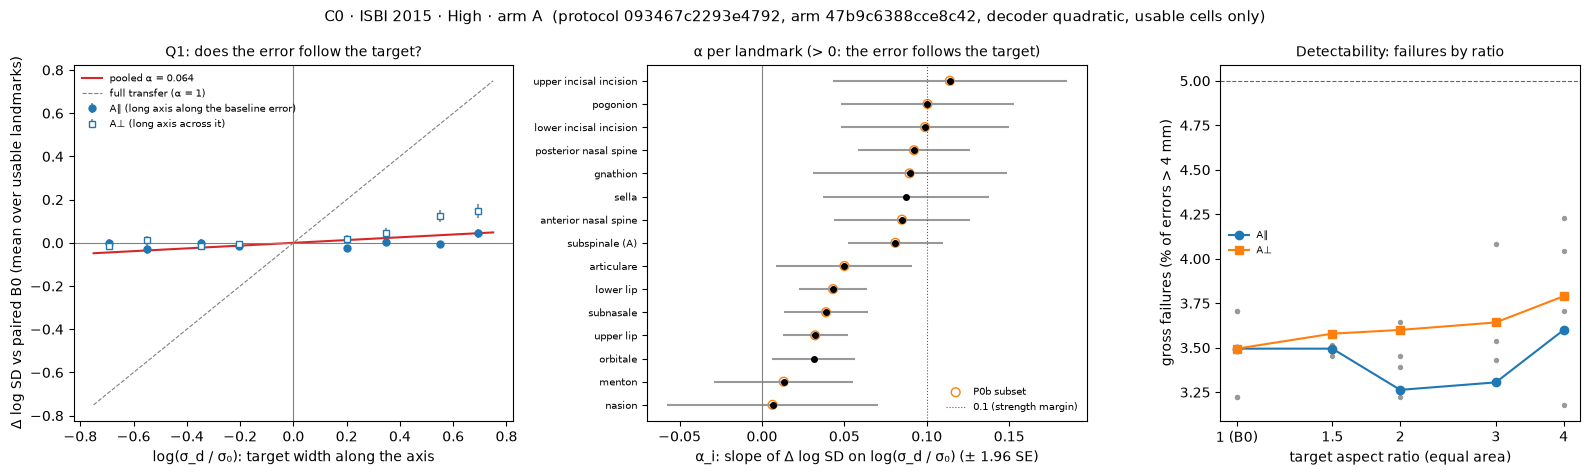

In [9]:
if HAVE_LOCK:
    try:
        fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1.1, 0.9]})
        ax = axs[0]
        u = base[base.usable]
        m = u.groupby(["arm", "ratio", "axis"]).agg(x=("x", "first"), y=("dlog_sd", "mean"), se=("dlog_sd", "sem")).reset_index()
        for arm, mk, lab in (("Apar", "o", "A∥ (long axis along the baseline error)"), ("Aperp", "s", "A⊥ (long axis across it)")):
            g = m[m.arm == arm]
            ax.errorbar(g.x, g.y, yerr=1.96 * g.se, fmt=mk, ms=5, mfc="C0" if arm == "Apar" else "white", mec="C0", ecolor="0.6",
                        capsize=0, label=lab)
        xs = np.linspace(-0.75, 0.75, 10)
        a_p = POOLED["variants"]["primary"].get("alpha") or 0.0
        ax.plot(xs, a_p * xs, color="C3", lw=1.5, label=f"pooled α = {a_p:.3f}")
        ax.plot(xs, xs, color="0.5", lw=0.8, ls="--", label="full transfer (α = 1)")
        ax.axhline(0, color="0.5", lw=0.8); ax.axvline(0, color="0.5", lw=0.8)
        ax.set_xlabel("log(σ_d / σ₀): target width along the axis")
        ax.set_ylabel("Δ log SD vs paired B0 (mean over usable landmarks)")
        ax.set_title("Q1: does the error follow the target?", fontsize=10)
        ax.legend(fontsize=7, frameon=False, loc="upper left")
        ax = axs[1]
        q = ALPHA.dropna(subset=["alpha"]).sort_values("alpha")
        yy = np.arange(len(q))
        ax.errorbar(q.alpha, yy, xerr=1.96 * q.alpha_se, fmt="o", ms=4, color="k", ecolor="0.6", capsize=0)
        ax.scatter(q.alpha[q.in_P0b], yy[q.in_P0b.values], s=40, facecolors="none", edgecolors="C1", label="P0b subset")
        ax.axvline(0, color="0.5", lw=0.8); ax.axvline(0.1, color="C3", lw=0.8, ls=":", label="0.1 (strength margin)")
        ax.set_yticks(yy); ax.set_yticklabels(q.name, fontsize=7)
        ax.set_xlabel("α_i: slope of Δ log SD on log(σ_d / σ₀) (± 1.96 SE)")
        ax.set_title("α per landmark (> 0: the error follows the target)", fontsize=10)
        ax.legend(fontsize=7, frameon=False, loc="lower right")
        ax = axs[2]
        for arm, mk in (("Apar", "o"), ("Aperp", "s")):
            g = ACC[ACC.arm.isin([arm, "B0"])].copy()
            g["arm"] = arm
            gg = g.groupby("ratio").fail_rate.median() * 100
            ax.plot(gg.index, gg.values, marker=mk, label={"Apar": "A∥", "Aperp": "A⊥"}[arm])
            ax.scatter(g.ratio, g.fail_rate * 100, s=8, color="0.6", zorder=0)
        ax.axhline(5, color="0.4", lw=0.8, ls="--")
        ax.set_xscale("log"); ax.set_xticks([1, 1.5, 2, 3, 4]); ax.set_xticklabels(["1 (B0)", "1.5", "2", "3", "4"]); ax.minorticks_off()
        ax.set_xlabel("target aspect ratio (equal area)")
        ax.set_ylabel("gross failures (% of errors > 4 mm)")
        ax.set_title("Detectability: failures by ratio", fontsize=10)
        ax.legend(fontsize=7, frameon=False)
        fig.suptitle(f"C0 · {DATASET} · {TIER} · arm A  (protocol {PROTOCOL_HASH}, arm {ARM_HASH}, decoder {PD}, usable cells only)",
                     fontsize=11)
        fig.tight_layout()
        fig.savefig(AGG / "arm_A_overview.png", dpi=150)
        plt.show()
    finally:
        _LOCK.unlink(missing_ok=True)

## 11. Results

In [10]:
print("checkpoints:", {s: sum(v == s for v in CKPT_STATUS.values()) for s in set(CKPT_STATUS.values())})
print((AGG / "alpha_pooled.json").read_text())

checkpoints: {'verified': 15, 'not present (DONE only)': 24}
{
 "protocol_hash": "093467c2293e4792",
 "arm_hash": "47b9c6388cce8c42",
 "primary_decoder": "quadratic",
 "max_fail_cell": 0.05,
 "min_obs": 8,
 "p0b_landmarks": [
  "nasion",
  "subspinale (A)",
  "supramentale (B)",
  "pogonion",
  "menton",
  "gnathion",
  "gonion",
  "lower incisal incision",
  "upper incisal incision",
  "upper lip",
  "lower lip",
  "subnasale",
  "soft-tissue pogonion",
  "posterior nasal spine",
  "anterior nasal spine",
  "articulare"
 ],
 "variants": {
  "primary": {
   "n_landmarks": 15,
   "alpha": 0.0642,
   "se": 0.009,
   "t": 7.141,
   "p_one_sided": 0.0,
   "lower95_one_sided": 0.0484,
   "ci95": [
    0.0449,
    0.0835
   ],
   "verdict": "transfer detected but weak (alpha > 0, lower bound <= 0.1)"
  },
  "P0b_Aperp_disagreement": {
   "n_landmarks": 13,
   "alpha": 0.1091,
   "se": 0.0202,
   "t": 5.404,
   "p_one_sided": 8e-05,
   "lower95_one_sided": 0.0732,
   "ci95": [
    0.0651,
   